# 01 - Exploratory data analysis

Goal: understand the shape of the ListenBrainz sample before modelling. How active are users, how skewed is track popularity, and how much data survives the sparsity filter?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from recsys.data import filter_sparse, load_listens

FIG = ROOT / 'results' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## Load

In [2]:
df = load_listens(ROOT / 'data/raw/listens.parquet')
meta_path = ROOT / 'data/raw/track_meta.parquet'
meta = pd.read_parquet(meta_path) if meta_path.exists() else None
summary = pd.Series({
    'listens': len(df),
    'users': df.user_id.nunique(),
    'tracks': df.track_id.nunique(),
    'first listen': df.listened_at.min(),
    'last listen': df.listened_at.max(),
})
summary

listens                    15659434
users                         39266
tracks                      3679245
first listen    2026-09-30 00:00:00
last listen     2026-10-16 00:33:46
dtype: object

## Listens per user
Heavy-tailed: a few very active users (or scrobbling bots) generate a large share of all listens.

count    39266.0
mean       398.8
std        971.3
min          1.0
25%         56.0
50%        172.0
75%        413.0
90%        827.0
99%       4311.0
max      50157.0
dtype: float64


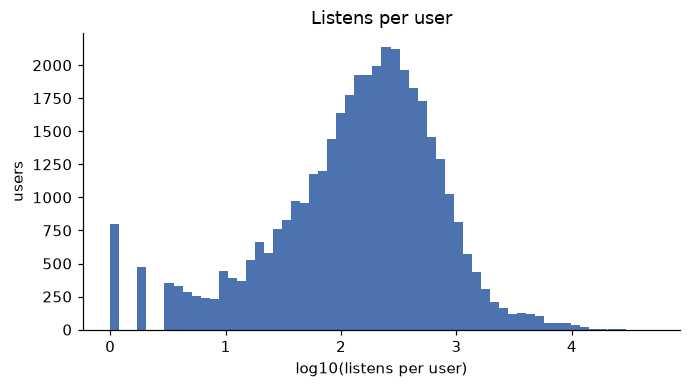

In [3]:
per_user = df.groupby('user_id').size()
print(per_user.describe(percentiles=[.25, .5, .75, .9, .99]).round(1))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.log10(per_user), bins=60, color='#4C72B0')
ax.set(xlabel='log10(listens per user)', ylabel='users', title='Listens per user')
fig.savefig(FIG / 'listens_per_user.png', bbox_inches='tight')

In [4]:
top1 = per_user.sort_values(ascending=False)
share = top1.head(max(1, len(top1) // 100)).sum() / len(df)
print(f'Top 1% of users produce {share:.1%} of listens')
print(f'Most active user: {top1.iloc[0]:,} listens '
      f'(~{top1.iloc[0] / ((df.listened_at.max() - df.listened_at.min()).days or 1):,.0f}/day) -- check for bots')

Top 1% of users produce 19.3% of listens
Most active user: 50,157 listens (~3,135/day) -- check for bots


## Distinct tracks per user and repeat listening

In [5]:
distinct = df.groupby('user_id')['track_id'].nunique()
repeat_ratio = per_user / distinct
print(distinct.describe(percentiles=[.5, .9]).round(1))
print(f'Median listens per distinct track (per user): {repeat_ratio.median():.2f}')

count    39266.0
mean       209.9
std        295.4
min          1.0
50%        122.0
90%        494.0
max      13052.0
Name: track_id, dtype: float64
Median listens per distinct track (per user): 1.21


## Popularity skew (the long tail)
If a small head of tracks dominates, a popularity baseline will be strong.

Top 0.1% of tracks = 27.4% of listens
Top 1.0% of tracks = 43.7% of listens
Top 10.0% of tracks = 68.5% of listens
Tracks played only once: 63.9%


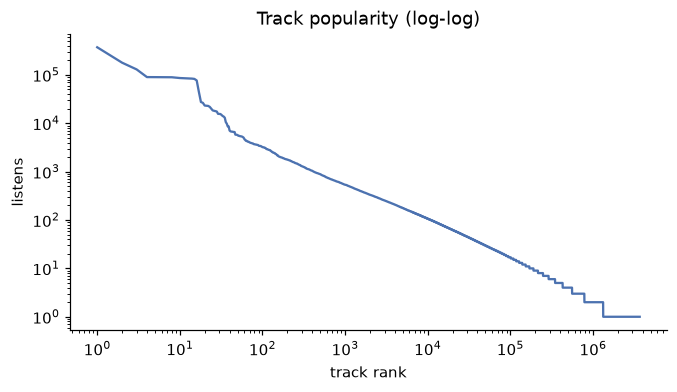

In [6]:
per_track = df.groupby('track_id').size().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.loglog(np.arange(1, len(per_track) + 1), per_track.to_numpy(), color='#4C72B0')
ax.set(xlabel='track rank', ylabel='listens', title='Track popularity (log-log)')
fig.savefig(FIG / 'long_tail.png', bbox_inches='tight')
for q in [0.001, 0.01, 0.1]:
    n = max(1, int(len(per_track) * q))
    print(f'Top {q:.1%} of tracks = {per_track.head(n).sum() / len(df):.1%} of listens')
print(f'Tracks played only once: {(per_track == 1).mean():.1%}')

In [7]:
if meta is not None:
    top = per_track.head(15).rename('listens').reset_index().merge(meta, on='track_id', how='left')
    display(top[['artist_name', 'recording_name', 'listens']])

,artist_name,recording_name,listens
0,BTS,SWIM,373115
1,BTS,NORMAL,179149
2,BTS,Come Over,130004
3,BTS,Hooligan,90229
4,BTS,Body to Body,90011
5,Agust D,해금,89758
6,BTS,2.0,89652
7,BTS,Aliens,89508
8,BTS,Into the Sun,87799
9,BTS,FYA,86274


## Activity over time
The time-based split puts the last 20% of listens in the test set, so check the timeline is roughly even.

80/20 time cutoff: 2026-10-13 15:04:39


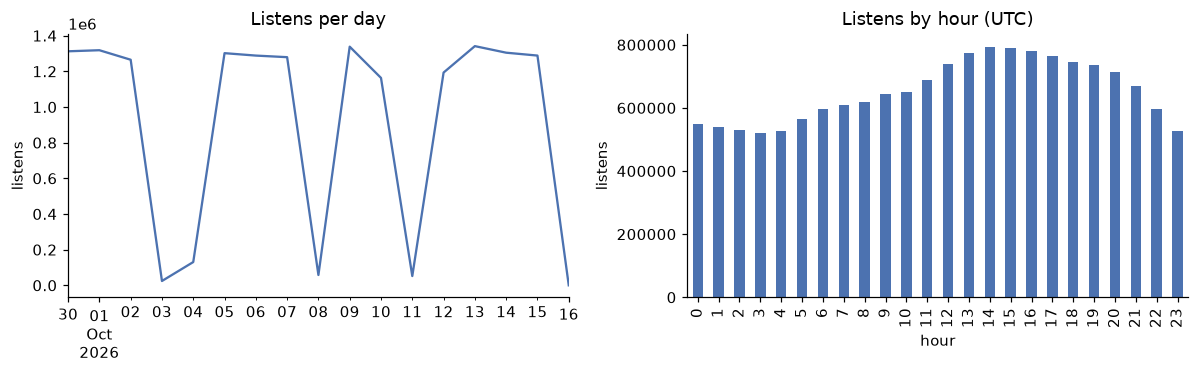

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df.set_index('listened_at').resample('D').size().plot(ax=axes[0], color='#4C72B0')
axes[0].set(title='Listens per day', xlabel='', ylabel='listens')
df.listened_at.dt.hour.value_counts().sort_index().plot.bar(ax=axes[1], color='#4C72B0')
axes[1].set(title='Listens by hour (UTC)', xlabel='hour', ylabel='listens')
fig.tight_layout(); fig.savefig(FIG / 'activity_over_time.png', bbox_inches='tight')
print('80/20 time cutoff:', df.listened_at.quantile(0.8))

## How much survives the sparsity filter?
`run_experiment.py` drops users/tracks with fewer than N listens. Compare thresholds to pick one.

In [9]:
rows = []
for n in [5, 10, 20, 50]:
    f = filter_sparse(df, n, n)
    nu, nt = f.user_id.nunique(), f.track_id.nunique()
    pairs = f[['user_id', 'track_id']].drop_duplicates().shape[0]
    rows.append({'min listens': n, 'listens kept': f'{len(f) / len(df):.1%}', 'users': nu, 'tracks': nt,
                 'density': f'{pairs / (nu * nt):.4%}'})
pd.DataFrame(rows)

,min listens,listens kept,users,tracks,density
0,5,70.4%,35127,428389,0.0289%
1,10,60.4%,31955,188984,0.0571%
2,20,50.8%,26515,80784,0.1210%
3,50,37.2%,14171,22105,0.4337%


## Notes for the README
Fill these in from the outputs above:
- Sample: _dates_, _#listens_, _#users_, _#tracks_ (before / after filtering)
- Popularity skew: top 1% of tracks = _X%_ of listens
- User activity: median _X_ listens/user; top 1% of users = _X%_ of listens
- Anything odd (bots, duplicate scrobbles, timezone effects)?